# Rusty Bargain: a model to value used cars and attract new buyers

**Ahmad Hassan** | AI Engineer and mentor

**Live app:** [FairTag](https://fairtag-car-valuation-application.streamlit.app/) · **App code:** [fairtag-car-valuation-application](https://github.com/ahmadhassan-aiops/fairtag-car-valuation-application)

Rusty Bargain buys and sells used cars and is building an app that tells a seller, in seconds, what their car is worth.
This notebook cleans 354,369 historical ads, compares six models on the three things the company cares about
(**prediction quality, prediction speed, training time**), tunes the best one, measures it once on held-out ads and
saves it for the app.

## Contents

1. Introduction: the task, the data, and an audit of the first version of this notebook
2. Data preparation: loading, cleaning (each step counted), car age
3. Exploratory analysis
4. Model comparison: six models, 5-fold cross-validation, quality, speed and training time
5. Tuning LightGBM
6. The final model: price range, one test on held-out ads, what drives prices
7. Saving the model
8. Conclusions

## 1 Introduction

### 1.1 The task

Build a model that predicts a car's market value (its asking price in euros) from its specification. RMSE is the
quality metric. Linear regression serves as a sanity check; tree ensembles and gradient boosting (LightGBM, and
optionally CatBoost and XGBoost) are the candidates.

### 1.2 The data

`car_data.csv`, one row per ad on a German classifieds site.

| Column | Meaning |
|---|---|
| `DateCrawled` | when the ad was downloaded |
| `VehicleType` | body type |
| `RegistrationYear`, `RegistrationMonth` | first registration |
| `Gearbox` | manual or auto |
| `Power` | horsepower |
| `Model`, `Brand` | model and brand |
| `Mileage` | kilometres, recorded by the site in steps up to 150,000 |
| `FuelType` | fuel |
| `NotRepaired` | whether the car has unrepaired damage |
| `DateCreated` | when the ad was created |
| `NumberOfPictures` | pictures in the ad |
| `PostalCode` | the seller's postal code |
| `LastSeen` | last time the ad was active |
| **`Price`** | **asking price in euros (target)** |

### 1.3 Audit of the first version of this notebook

The first version reported CatBoost with an RMSE of **984**, far better than every other model (about 1,520 to 2,620).
An audit found why, and several other problems. This version fixes all of them.

| Problem in the first version | Effect | Fix in this version |
|---|---|---|
| A `PriceGroup` column was built by binning the **target** price, then given to CatBoost as a feature | Target leakage: the model was told the price band of every car, including test cars. The 984 came from this | No feature is derived from the price |
| Zero `Power` values were filled with the median power of the car's **price group** | Leakage again, and impossible in the app, where the price is unknown | Impossible power values are set to missing; LightGBM handles missing values |
| Only exact duplicate rows were removed (262) | The same ad crawled twice with different crawl dates stayed in (about 10,000 copies), so copies of training ads sat in the test set | Duplicates are found ignoring the crawl dates |
| Prices above 14,425 euros were deleted as "outliers" (5% of ads) | They are real, expensive cars; the model could not price them | All prices from 100 to 20,000 euros are kept |
| Registration years from 1000 to 9999 were kept | Impossible ages | Years before 1950 or after the ad date are removed |
| The source labels diesel cars "gasoline" | Mislabelled fuel | Relabelled diesel |
| `RegistrationMonth` and the ad date were dropped | Age known only to the year | Age to the month at the time of the ad |
| `Model` and `Brand` were dropped for every model except CatBoost | The strongest identity features were missing for linear regression, trees and boosting | All models get all nine features |
| Each model was "tested on the test dataset" while choosing between models | The test set was used for model selection | Models are compared and tuned by cross-validation on the training split; the test set is used once |
| The summary table mixed cross-validated and test RMSE, and timings from different settings | Not comparable | One table: same folds, same features, timed the same way |

## 2 Data preparation

### 2.1 Libraries

In [1]:
import json
import time
import warnings
from datetime import date
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

try:
    import catboost as cb
except ImportError:  # optional
    cb = None

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
SEED = 42
print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| catboost", cb.__version__ if cb else "not installed")

lightgbm 4.7.0 | xgboost 3.2.0 | catboost 1.2.10


### 2.2 Load the data

In [2]:
raw = pd.read_csv("car_data.csv")
print(raw.shape)
raw.head()

(354369, 16)


,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DateCrawled        354369 non-null  str  
 1   Price              354369 non-null  int64
 2   VehicleType        316879 non-null  str  
 3   RegistrationYear   354369 non-null  int64
 4   Gearbox            334536 non-null  str  
 5   Power              354369 non-null  int64
 6   Model              334664 non-null  str  
 7   Mileage            354369 non-null  int64
 8   RegistrationMonth  354369 non-null  int64
 9   FuelType           321474 non-null  str  
 10  Brand              354369 non-null  str  
 11  NotRepaired        283215 non-null  str  
 12  DateCreated        354369 non-null  str  
 13  NumberOfPictures   354369 non-null  int64
 14  PostalCode         354369 non-null  int64
 15  LastSeen           354369 non-null  str  
dtypes: int64(7), str(9)
memory usage: 69.5 MB


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,354369.0,4416.656776,4514.158514,0.0,1050.0,2700.0,6400.0,20000.0
RegistrationYear,354369.0,2004.234448,90.227958,1000.0,1999.0,2003.0,2008.0,9999.0
Power,354369.0,110.094337,189.850405,0.0,69.0,105.0,143.0,20000.0
Mileage,354369.0,128211.172535,37905.341530,5000.0,125000.0,150000.0,150000.0,150000.0
RegistrationMonth,354369.0,5.714645,3.726421,0.0,3.0,6.0,9.0,12.0
NumberOfPictures,354369.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
PostalCode,354369.0,50508.689087,25783.096248,1067.0,30165.0,49413.0,71083.0,99998.0


In [5]:
# Missing values per column (share of rows)
raw.isna().mean().sort_values(ascending=False).round(3)

NotRepaired          0.201
VehicleType          0.106
FuelType             0.093
Gearbox              0.056
Model                0.056
Price                0.000
RegistrationYear     0.000
DateCrawled          0.000
Mileage              0.000
Power                0.000
RegistrationMonth    0.000
Brand                0.000
DateCreated          0.000
NumberOfPictures     0.000
PostalCode           0.000
LastSeen             0.000
dtype: float64

**Findings**
- 354,369 ads and 16 columns. Five categorical columns have missing values, `NotRepaired` most often (about 20%).
- `Price` and `Power` start at 0, `RegistrationYear` runs from 1000 to 9999: there are typing errors and placeholders.
- `NumberOfPictures` is always 0 and carries no information.

In [6]:
print("NumberOfPictures values:", raw["NumberOfPictures"].unique())
print("Fuel types:", raw["FuelType"].value_counts(dropna=False).to_dict())

NumberOfPictures values: [0]
Fuel types: {'petrol': 216352, 'gasoline': 98720, nan: 32895, 'lpg': 5310, 'cng': 565, 'hybrid': 233, 'other': 204, 'electric': 90}


The fuel list has `petrol` and `gasoline` but no `diesel`. In the German source the categories are *benzin* and
*diesel*; `gasoline` (28% of ads, matching diesel's share of German used cars) is the diesel category mistranslated.
Gasoline cars also have higher median power, as diesels in this market do:

In [7]:
raw.groupby("FuelType")["Power"].median()

FuelType
cng          97.0
electric     19.0
gasoline    131.0
hybrid       99.0
lpg         140.0
other         1.0
petrol       99.0
Name: Power, dtype: float64

### 2.3 Cleaning

Each step is counted. The same function is used in the app's `train.py`.

In [8]:
CATEGORICAL = ["Brand", "Model", "VehicleType", "Gearbox", "FuelType", "NotRepaired"]
NUMERIC = ["Age", "Power", "Mileage"]
FEATURES = CATEGORICAL + NUMERIC
MIN_PRICE, MIN_YEAR, POWER_RANGE, MAX_KM_FIRST_YEAR = 100, 1950, (20, 600), 50000


def car_age(reg_year, reg_month, ad_year, ad_month):
    """Age in years at the time of the ad; month 0 (not given) counts as mid-year; never below 0."""
    reg_month = np.where(np.asarray(reg_month) == 0, 6, reg_month)
    age = np.asarray(ad_year - np.asarray(reg_year), dtype=float) + (np.asarray(ad_month) - reg_month) / 12
    return np.clip(age, 0, None)


def clean(raw, report):
    d = raw.copy()
    d["DateCreated"] = pd.to_datetime(d["DateCreated"], dayfirst=True)
    n = len(d)
    d = d.drop_duplicates(subset=[c for c in d.columns if c not in ("DateCrawled", "LastSeen")])
    report["duplicates"] = n - len(d)
    report["low_price"] = int((d["Price"] < MIN_PRICE).sum())
    d = d[d["Price"] >= MIN_PRICE]
    ok = (d["RegistrationYear"] >= MIN_YEAR) & (d["RegistrationYear"] <= d["DateCreated"].dt.year)
    report["bad_year"] = int((~ok).sum())
    d = d[ok].copy()
    report["gasoline"] = int((d["FuelType"] == "gasoline").sum())
    d["FuelType"] = d["FuelType"].replace({"gasoline": "diesel"})
    bad = (d["Power"] < POWER_RANGE[0]) | (d["Power"] > POWER_RANGE[1])
    report["power_zero"], report["bad_power"] = int((d["Power"] == 0).sum()), int(bad.sum())
    d.loc[bad, "Power"] = np.nan
    d["Age"] = car_age(d["RegistrationYear"].to_numpy(), d["RegistrationMonth"].to_numpy(),
                       d["DateCreated"].dt.year.to_numpy(), d["DateCreated"].dt.month.to_numpy())
    wrong = (d["Age"] < 1) & (d["Mileage"] > MAX_KM_FIRST_YEAR)
    report["new_but_driven"] = int(wrong.sum())
    d = d[~wrong].copy()
    report["missing"] = {c: int(d[c].isna().sum()) for c in CATEGORICAL}
    for c in CATEGORICAL:
        d[c] = d[c].fillna("unknown").astype(str)
    d["Power"], d["Mileage"] = d["Power"].astype(float), d["Mileage"].astype(float)
    return d.reset_index(drop=True)


steps = {}
df = clean(raw, steps)
print(f"{len(raw):,} ads -> {len(df):,} clean ads")
steps

354,369 ads -> 309,303 clean ads


{'duplicates': 10194,
 'low_price': 13036,
 'bad_year': 13589,
 'gasoline': 91447,
 'power_zero': 30989,
 'bad_power': 31665,
 'new_but_driven': 8247,
 'missing': {'Brand': 0,
  'Model': 13837,
  'VehicleType': 10440,
  'Gearbox': 13144,
  'FuelType': 19605,
  'NotRepaired': 53536}}

What each step does and why:

| Step | Rule | Why |
|---|---|---|
| Reposts | Rows identical apart from `DateCrawled` and `LastSeen` are kept once | The same ad crawled twice; copies would leak between training and test |
| Placeholder prices | Asking price under 100 euros removed | 0, 1 or 99 euros are placeholders, not prices |
| Impossible years | Registration before 1950 or after the ad's year removed | Typing errors (1000, 9999 and so on) |
| Fuel | `gasoline` relabelled `diesel` | Translation error in the source |
| Impossible power | Under 20 or over 600 hp set to missing | 0 hp means "not given"; values like 17,000 hp are typing errors. LightGBM learns what missing power means instead of guessing it |
| New but heavily driven | Under a year old with more than 50,000 km removed | Mostly ads that give the ad year as the registration year (150,000 km, about 1,000 euros): the age is wrong |
| Missing categories | Kept as their own value `unknown` | A seller leaving a field empty is information |

In [9]:
df["Age"].describe().round(2)

count    309303.00
mean         13.46
std           6.48
min           0.00
25%           9.08
50%          13.08
75%          17.00
max          66.25
Name: Age, dtype: float64

## 3 Exploratory analysis

### 3.1 The target: asking price

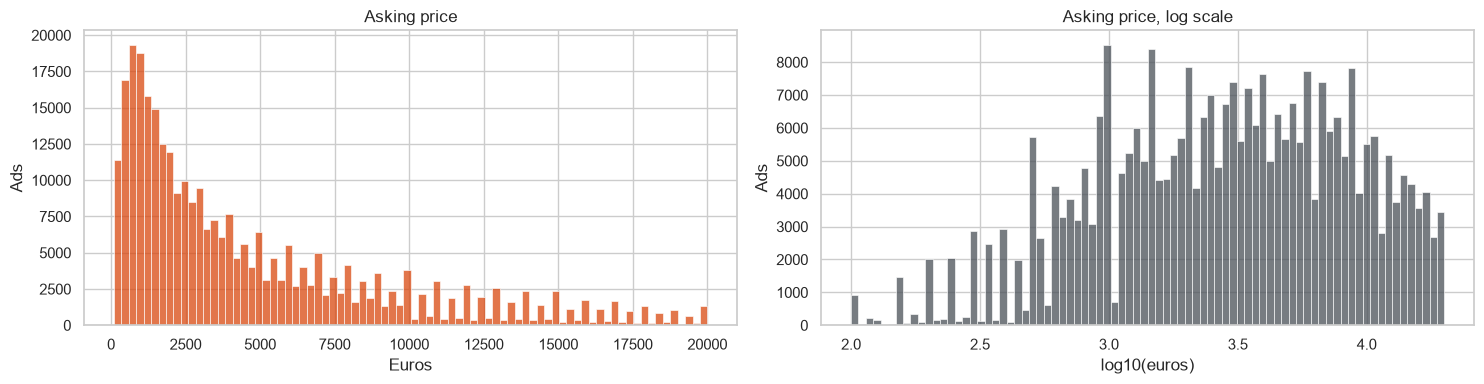

count    309303.0
mean       4688.0
std        4559.0
min         100.0
25%        1250.0
50%        2999.0
75%        6800.0
max       20000.0
Name: Price, dtype: float64


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df["Price"], bins=80, ax=ax[0], color="#d9480f")
ax[0].set(title="Asking price", xlabel="Euros", ylabel="Ads")
sns.histplot(np.log10(df["Price"]), bins=80, ax=ax[1], color="#495057")
ax[1].set(title="Asking price, log scale", xlabel="log10(euros)", ylabel="Ads")
plt.tight_layout(); plt.show()
print(df["Price"].describe().round(0))

Prices are right-skewed: median about 3,000 euros, a long tail to the site's cap of 20,000. The tail is real, so it is
kept; whether a log target helps is tested in section 4.

### 3.2 Age, mileage and power

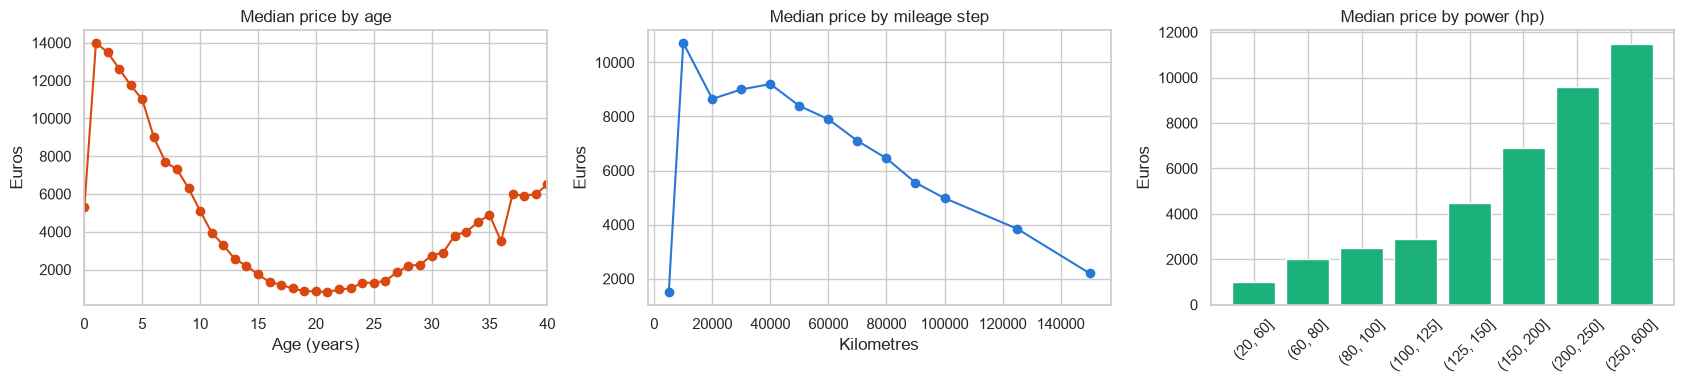

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
age_med = df.groupby(df["Age"].round())["Price"].median()
ax[0].plot(age_med.index, age_med.values, marker="o", color="#d9480f")
ax[0].set(title="Median price by age", xlabel="Age (years)", ylabel="Euros", xlim=(0, 40))
km_med = df.groupby("Mileage")["Price"].median()
ax[1].plot(km_med.index, km_med.values, marker="o", color="#2a78d6")
ax[1].set(title="Median price by mileage step", xlabel="Kilometres", ylabel="Euros")
p = pd.cut(df["Power"], [20, 60, 80, 100, 125, 150, 200, 250, 600])
pw_med = df.groupby(p, observed=True)["Price"].median()
ax[2].bar([str(i) for i in pw_med.index], pw_med.values, color="#1baf7a")
ax[2].set(title="Median price by power (hp)", ylabel="Euros"); ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [12]:
print("Ads at each mileage step:")
print((df["Mileage"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())

Ads at each mileage step:
Mileage
5000.0       1.4
10000.0      0.3
20000.0      1.1
30000.0      1.3
40000.0      1.5
50000.0      1.9
60000.0      2.2
70000.0      2.6
80000.0      2.9
90000.0      3.4
100000.0     4.3
125000.0    10.5
150000.0    66.6


**Findings**
- Prices fall steadily with age for about 20 years (median under 1,000 euros at 19 to 21 years), then rise again:
  cars over 30 are classics.
- Two thirds of ads are at the top mileage step (150,000 km or more), so mileage separates cars less than expected.
- Price rises with power at every step.
- The 5,000 km step is cheaper than 20,000 to 90,000 km: among older cars it mostly holds incomplete listings, which
  the model learns as such (stated as a limit in the app).

### 3.3 Categories

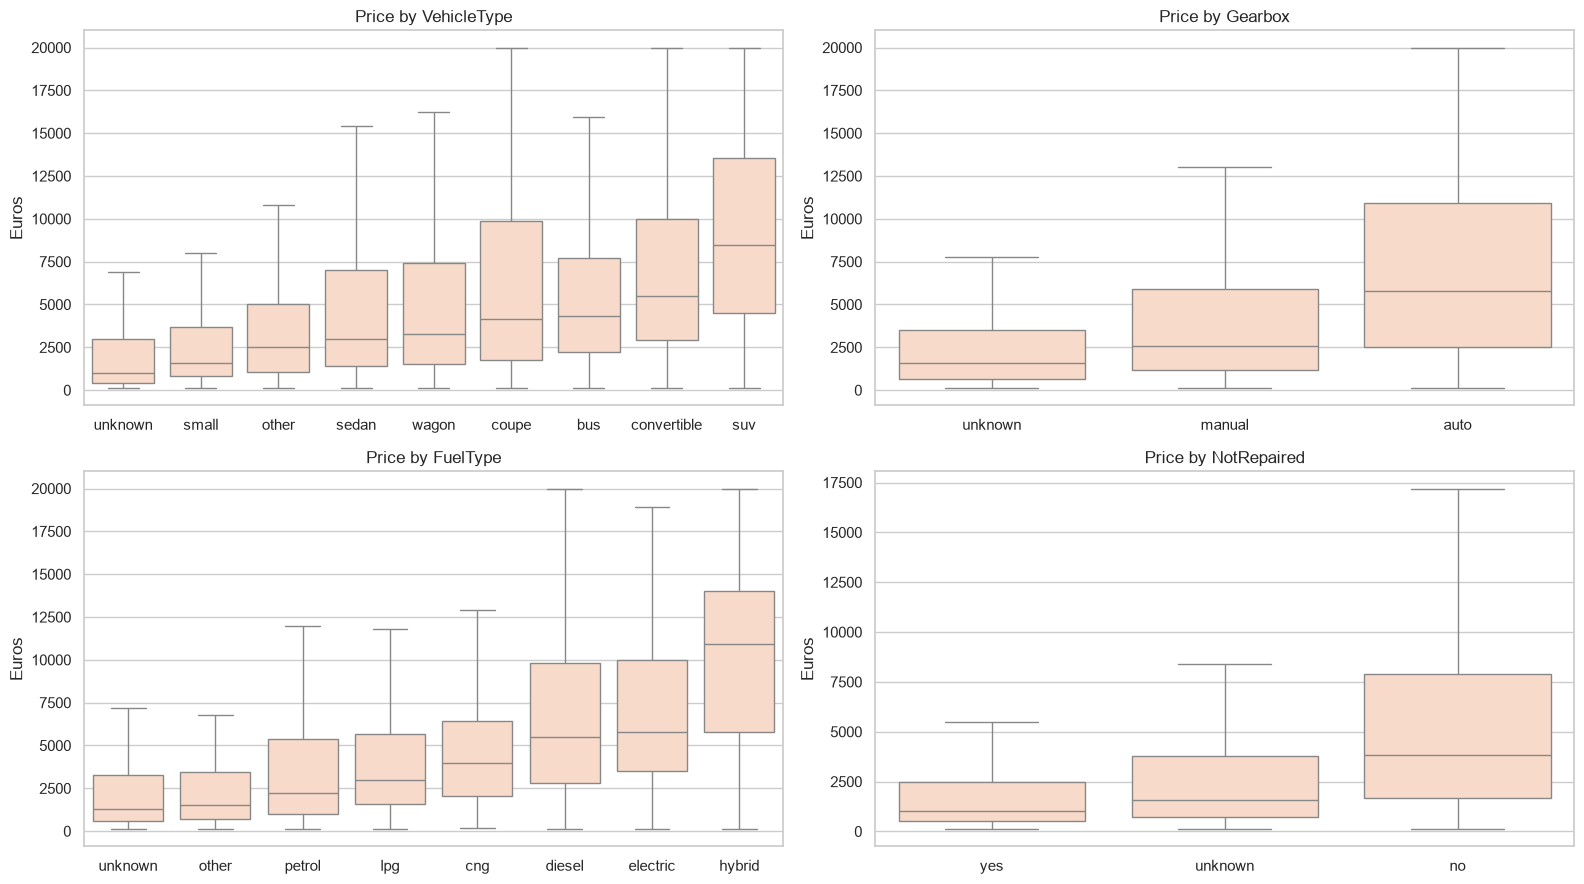

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for a, col in zip(ax.flat, ["VehicleType", "Gearbox", "FuelType", "NotRepaired"]):
    order = df.groupby(col)["Price"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="Price", order=order, ax=a, color="#ffd8c2", showfliers=False)
    a.set(title=f"Price by {col}", xlabel="", ylabel="Euros")
plt.tight_layout(); plt.show()

In [14]:
top = df["Brand"].value_counts().head(15).index
brand = df[df["Brand"].isin(top)].groupby("Brand").agg(ads=("Price", "size"), median_price=("Price", "median"),
                                                        median_age=("Age", "median"))
brand.sort_values("ads", ascending=False).round(1)

,ads,median_price,median_age
Brand,,,
volkswagen,66011,2990.0,13.9
opel,33967,1680.0,14.6
bmw,32884,5000.0,13.2
mercedes_benz,28834,4500.0,13.9
audi,26128,5000.0,12.2
ford,21884,1800.0,13.0
renault,15288,1400.0,13.8
peugeot,9756,2300.0,12.0
fiat,8287,1650.0,13.0


**Findings**
- SUVs ask the most (median 8,500 euros), then convertibles, vans and coupés; small cars the least (1,600).
- Automatics ask more than twice what manuals ask (they are also newer and more powerful on average).
- Unrepaired damage goes with a median price about a quarter of undamaged cars' (1,000 against 3,850 euros);
  "not given" sits in between.
- Volkswagen alone is a fifth of the ads. Premium German brands (BMW, Mercedes-Benz, Audi) ask about three times what
  Opel, Ford or Renault ask, at similar ages.

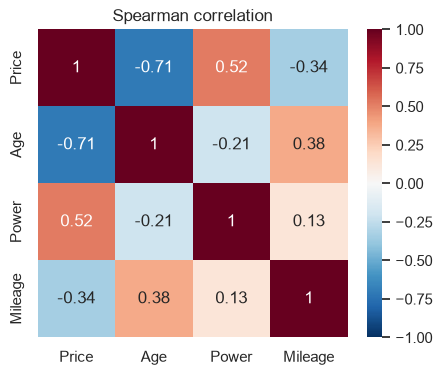

In [15]:
num = df[["Price", "Age", "Power", "Mileage"]].corr(method="spearman").round(2)
plt.figure(figsize=(5, 4)); sns.heatmap(num, annot=True, cmap="RdBu_r", vmin=-1, vmax=1); plt.title("Spearman correlation"); plt.show()

## 4 Model comparison

One random 80/20 split; the 20% test set is not touched until section 6. All models get the same nine features and are
scored with 5-fold cross-validation on the training split. Fit time is per fold; prediction time is for one car.

In [16]:
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
X, y = train[FEATURES].reset_index(drop=True), train["Price"].to_numpy(float)
print(f"training {len(train):,} ads, test {len(test):,} ads")
FOLDS = list(KFold(5, shuffle=True, random_state=0).split(X))


def one_hot():
    return ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
                              ("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC)])


def ordinal():
    return ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
                              ("n", SimpleImputer(strategy="median"), NUMERIC)])


class AsCategory:
    """Pass the categorical columns as pandas categories (LightGBM and XGBoost split on them natively)."""
    def __init__(self, model): self.model = model
    def _x(self, X):
        X = X.copy()
        for c in CATEGORICAL:
            X[c] = pd.Categorical(X[c].where(X[c].isin(self.cats[c])), categories=self.cats[c])
        return X
    def fit(self, X, y):
        self.cats = {c: sorted(X[c].unique()) for c in CATEGORICAL}
        self.model.fit(self._x(X), y); return self
    def predict(self, X): return self.model.predict(self._x(X))


MODELS = {
    "Linear regression (one-hot)": lambda: make_pipeline(one_hot(), Ridge(alpha=1.0)),
    "Decision tree": lambda: make_pipeline(ordinal(), DecisionTreeRegressor(max_depth=20, min_samples_leaf=10, random_state=0)),
    "Random forest": lambda: make_pipeline(ordinal(), RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.6,
                                                                            n_jobs=4, random_state=0)),
    "LightGBM": lambda: AsCategory(lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, num_leaves=127, subsample=0.8,
                                                     subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)),
    "XGBoost": lambda: AsCategory(xgb.XGBRegressor(n_estimators=1500, learning_rate=0.05, max_depth=9, subsample=0.8,
                                                   colsample_bytree=0.8, enable_categorical=True, tree_method="hist",
                                                   max_cat_to_onehot=1, random_state=0, n_jobs=-1)),
}
if cb is not None:
    MODELS["CatBoost"] = lambda: cb.CatBoostRegressor(iterations=2000, learning_rate=0.1, depth=8, cat_features=CATEGORICAL,
                                                     verbose=0, random_seed=0, thread_count=-1)


def scores(y, p):
    e = p - y
    return dict(rmse=float(np.sqrt(np.mean(e ** 2))), mae=float(np.mean(np.abs(e))), mdape=float(np.median(np.abs(e) / y)),
                r2=float(1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)))


def cross_validate(make, log_target=False):
    oof, fit_t = np.zeros(len(y)), []
    for a, b in FOLDS:
        m = make(); t = time.perf_counter()
        m.fit(X.iloc[a], np.log(y[a]) if log_target else y[a]); fit_t.append(time.perf_counter() - t)
        p = m.predict(X.iloc[b]); oof[b] = np.exp(p) if log_target else p
    one = X.iloc[[0]]; t = time.perf_counter()
    for _ in range(20):
        m.predict(one)
    return dict(**scores(y, oof), fit_s=float(np.mean(fit_t)), predict_ms=(time.perf_counter() - t) / 20 * 1000)

training 247,442 ads, test 61,861 ads


#### 4.1 Raw or log price?

In [17]:
target_test = {"raw price": cross_validate(MODELS["LightGBM"]), "log price": cross_validate(MODELS["LightGBM"], log_target=True)}
pd.DataFrame(target_test).T[["rmse", "mae", "mdape", "r2"]].round(3)

,rmse,mae,mdape,r2
raw price,1518.266,929.435,0.193,0.889
log price,1605.001,954.888,0.197,0.876


Predicting the log of the price is worse on every measure here, including RMSE in euros, the brief's metric. The
models below predict the raw price.

#### 4.2 Six models

In [18]:
results = {}
for name, make in MODELS.items():
    results[name] = cross_validate(make)
    print(f"{name:30s} RMSE {results[name]['rmse']:7,.0f}   fit {results[name]['fit_s']:6.1f} s", flush=True)
comparison = pd.DataFrame(results).T
comparison.round({"rmse": 0, "mae": 0, "mdape": 3, "r2": 3, "fit_s": 1, "predict_ms": 1})

Linear regression (one-hot)    RMSE   2,631   fit    1.2 s


Decision tree                  RMSE   1,832   fit    0.8 s


Random forest                  RMSE   1,590   fit    9.4 s


LightGBM                       RMSE   1,518   fit    7.4 s


XGBoost                        RMSE   1,540   fit   18.6 s


CatBoost                       RMSE   1,548   fit  158.0 s


,rmse,mae,mdape,r2,fit_s,predict_ms
Linear regression (one-hot),2631.0,1807.0,0.381,0.668,1.2,4.2
Decision tree,1832.0,1120.0,0.224,0.839,0.8,3.5
Random forest,1590.0,975.0,0.197,0.879,9.4,30.4
LightGBM,1518.0,929.0,0.193,0.889,7.4,15.3
XGBoost,1540.0,932.0,0.192,0.886,18.6,14.2
CatBoost,1548.0,958.0,0.199,0.885,158.0,1.4


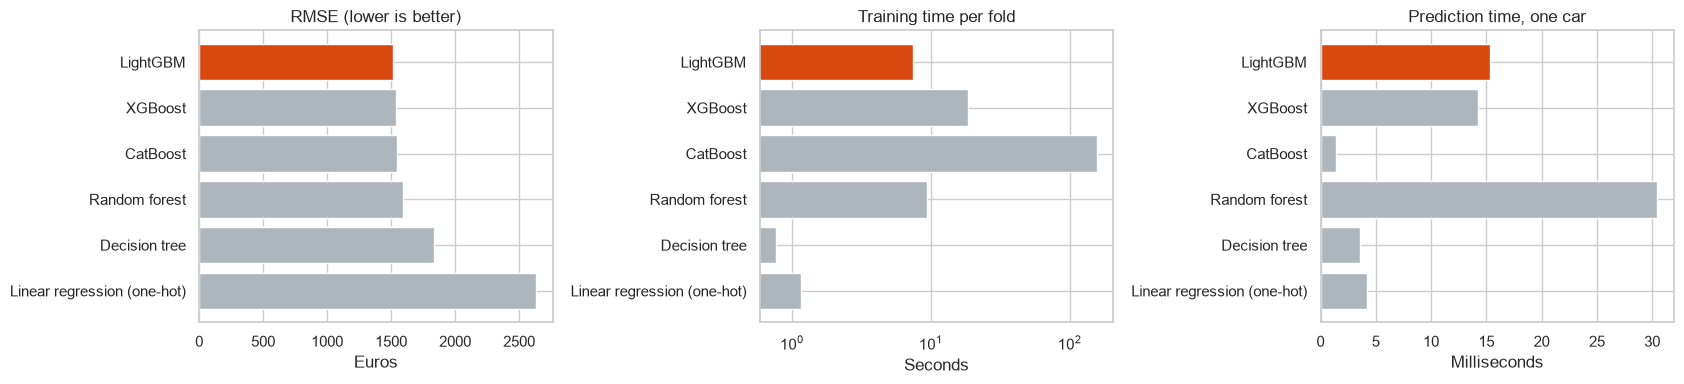

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
order = comparison.sort_values("rmse").index
colors = ["#d9480f" if m == "LightGBM" else "#adb5bd" for m in order]
ax[0].barh(order, comparison.loc[order, "rmse"], color=colors); ax[0].set(title="RMSE (lower is better)", xlabel="Euros")
ax[1].barh(order, comparison.loc[order, "fit_s"], color=colors); ax[1].set(title="Training time per fold", xlabel="Seconds", xscale="log")
ax[2].barh(order, comparison.loc[order, "predict_ms"], color=colors); ax[2].set(title="Prediction time, one car", xlabel="Milliseconds")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()

**Findings**
- Every model beats the linear regression sanity check by a wide margin; the gradient-boosting models are best.
- LightGBM has the lowest RMSE and trains in seconds. XGBoost is close but slower, CatBoost is close but trains more than
  20 times slower, and the random forest is both less accurate and the slowest to predict.
- LightGBM is chosen and tuned.

## 5 Tuning LightGBM

Random search over 24 settings, each scored by 5-fold cross-validation on the training split with early stopping
inside each fold (stop when 100 rounds bring no improvement on that fold's validation part).

In [20]:
Xc = X.copy()
for c in CATEGORICAL:
    Xc[c] = Xc[c].astype("category")
rng = np.random.default_rng(7)
search = []
for i in range(24):
    p = dict(learning_rate=float(rng.choice([0.03, 0.05, 0.08])), num_leaves=int(rng.choice([63, 127, 255, 511])),
             min_child_samples=int(rng.choice([10, 20, 40, 80])), subsample=float(rng.choice([0.7, 0.8, 1.0])), subsample_freq=1,
             colsample_bytree=float(rng.choice([0.6, 0.8, 1.0])), reg_lambda=float(rng.choice([0, 1, 5, 20])),
             cat_smooth=float(rng.choice([5, 10, 30])), min_data_per_group=int(rng.choice([20, 50, 100])),
             max_cat_threshold=int(rng.choice([32, 64])))
    fold_rmse, rounds, t = [], [], time.perf_counter()
    for a, b in FOLDS:
        m = lgb.LGBMRegressor(n_estimators=5000, verbose=-1, random_state=0, **p)
        m.fit(Xc.iloc[a], y[a], eval_X=Xc.iloc[b], eval_y=y[b], callbacks=[lgb.early_stopping(100, verbose=False)])
        fold_rmse.append(np.sqrt(np.mean((y[b] - m.predict(Xc.iloc[b])) ** 2))); rounds.append(m.best_iteration_)
    search.append(dict(**p, rmse=float(np.mean(fold_rmse)), fold_sd=float(np.std(fold_rmse)), trees=int(np.median(rounds)),
                       minutes=round((time.perf_counter() - t) / 60, 1)))
    print(i, round(search[-1]["rmse"]), search[-1]["trees"], flush=True)
search = pd.DataFrame(search).sort_values("rmse")
search.head(8)

0 1514 528


1 1516 2731


2 1517 1897


3 1517 1130


4 1515 449


5 1524 2232


... (15 outputs left out)

21 1519 2199


22 1522 1889


23 1517 1281


,learning_rate,num_leaves,min_child_samples,subsample,subsample_freq,colsample_bytree,reg_lambda,cat_smooth,min_data_per_group,max_cat_threshold,rmse,fold_sd,trees,minutes
7,0.03,511,10,0.7,1,0.6,20.0,30.0,100,32,1511.662698,14.437120,1079,1.6
19,0.05,255,40,0.7,1,0.8,20.0,10.0,20,32,1512.069367,14.025655,802,0.7
9,0.03,511,80,0.7,1,0.8,20.0,30.0,100,64,1512.299371,15.562126,1096,1.7
0,0.08,255,40,1.0,1,0.8,20.0,30.0,20,32,1514.255619,13.078696,528,0.4
10,0.03,255,20,0.7,1,0.6,5.0,30.0,50,64,1514.378434,13.422376,1301,1.1
16,0.05,511,10,0.8,1,0.8,0.0,30.0,100,32,1514.384426,16.249214,289,0.5
4,0.08,255,20,1.0,1,0.8,0.0,30.0,20,64,1515.175189,15.047824,449,0.3
12,0.05,127,10,0.7,1,0.8,20.0,10.0,50,64,1515.705915,13.896652,1245,0.7


In [21]:
best = search.iloc[0]
PARAMS = dict(objective="regression", learning_rate=float(best.learning_rate), num_leaves=int(best.num_leaves),
              min_child_samples=int(best.min_child_samples), subsample=float(best.subsample), subsample_freq=1,
              colsample_bytree=float(best.colsample_bytree), reg_lambda=float(best.reg_lambda), cat_smooth=float(best.cat_smooth),
              min_data_per_group=int(best.min_data_per_group), max_cat_threshold=int(best.max_cat_threshold),
              n_estimators=int(best.trees), random_state=0, verbose=-1)
print(f"Best setting: cross-validated RMSE {best.rmse:,.0f} (fold spread {best.fold_sd:.0f})")
print(f"Spread across all 24 settings: {search.rmse.min():,.0f} to {search.rmse.max():,.0f}")
PARAMS

Best setting: cross-validated RMSE 1,512 (fold spread 14)
Spread across all 24 settings: 1,512 to 1,525


{'objective': 'regression',
 'learning_rate': 0.03,
 'num_leaves': 511,
 'min_child_samples': 10,
 'subsample': 0.7,
 'subsample_freq': 1,
 'colsample_bytree': 0.6,
 'reg_lambda': 20.0,
 'cat_smooth': 30.0,
 'min_data_per_group': 100,
 'max_cat_threshold': 32,
 'n_estimators': 1079,
 'random_state': 0,
 'verbose': -1}

The differences between settings are about the size of the fold-to-fold spread: once the model is large enough, the
data, not the settings, limits accuracy. The best setting is used, with its median best tree count as a fixed number
of trees.

**The model deployed in the app.** Because the settings differ by noise, the app ships a lighter setting from this
same search rather than the best one: the setting in row `4` of the table above (255 leaves, learning rate 0.08), with a fixed 512 trees. Rebuilt
by the app's `train.py` on the same split, it scores 1,516 euros in cross-validation and 1,502 on the held-out ads,
against 1,512 and 1,500 for the best setting below, in a file of 11 MB instead of 48 MB, which loads faster and
explains each price faster on a free cloud server.

## 6 The final model

### 6.1 A price range from cross-validated errors

A single price hides how much asking prices vary for similar cars. Out-of-fold predictions on the training split give
honest errors; in 10 bands of predicted price, the 10th and 90th percentiles of real/predicted price give an 80% range.

In [22]:
cats = {c: sorted(train[c].unique().tolist()) for c in CATEGORICAL}


def frame(d):
    x = d[FEATURES].copy()
    for c in CATEGORICAL:
        x[c] = pd.Categorical(x[c].where(x[c].isin(cats[c])), categories=cats[c])
    return x


Xf, Xt, yt = frame(train), frame(test), test["Price"].to_numpy(float)
oof = np.zeros(len(y))
for a, b in FOLDS:
    oof[b] = np.maximum(lgb.LGBMRegressor(**PARAMS).fit(Xf.iloc[a], y[a]).predict(Xf.iloc[b]), MIN_PRICE)
cv = scores(y, oof)
edges = [0.0] + np.quantile(oof, np.linspace(0, 1, 11))[1:-1].tolist()
band = np.clip(np.searchsorted(edges, oof, side="right") - 1, 0, 9)
ratio = y / oof
low = [float(np.quantile(ratio[band == k], 0.10)) for k in range(10)]
high = [float(np.quantile(ratio[band == k], 0.90)) for k in range(10)]
print(f"cross-validated RMSE {cv['rmse']:,.0f}")
pd.DataFrame({"from": np.round(edges), "low x": np.round(low, 2), "high x": np.round(high, 2)})

cross-validated RMSE 1,512


,from,low x,high x
0,0.0,0.40,2.04
1,789.0,0.43,1.62
2,1176.0,0.45,1.54
3,1638.0,0.49,1.50
4,2259.0,0.55,1.42
5,3084.0,0.60,1.37
6,4199.0,0.65,1.32
7,5752.0,0.70,1.30
8,7939.0,0.74,1.28
9,11411.0,0.82,1.20


### 6.2 Train on the whole training split and test once

In [23]:
t = time.perf_counter()
final = lgb.LGBMRegressor(**PARAMS).fit(Xf, y)
fit_s = time.perf_counter() - t
pred = np.maximum(final.predict(Xt), MIN_PRICE)
tb = np.clip(np.searchsorted(edges, pred, side="right") - 1, 0, 9)
lo, hi = np.maximum(pred * np.asarray(low)[tb], MIN_PRICE), pred * np.asarray(high)[tb]
held_out = scores(yt, pred)
held_out.update(within_20=float(np.mean(np.abs(pred - yt) / yt <= 0.2)), range_coverage=float(np.mean((yt >= lo) & (yt <= hi))))
t = time.perf_counter()
for _ in range(50):
    final.predict(Xt.iloc[[0]])
predict_ms = (time.perf_counter() - t) / 50 * 1000
print(f"Training time {fit_s:.1f} s, prediction {predict_ms:.1f} ms per car")
pd.Series(held_out).round(3)

Training time 16.0 s, prediction 4.3 ms per car


rmse              1500.198
mae                916.610
mdape                0.190
r2                   0.891
within_20            0.517
range_coverage       0.804
dtype: float64

In [24]:
bands = pd.cut(yt, [100, 1000, 3000, 6000, 10000, 20001], right=False,
               labels=["100-999", "1,000-2,999", "3,000-5,999", "6,000-9,999", "10,000-20,000"])
err = pd.DataFrame({"band": bands, "abs_err": np.abs(pred - yt), "ape": np.abs(pred - yt) / yt, "bias": pred - yt,
                    "in_range": (yt >= lo) & (yt <= hi)})
err.groupby("band", observed=True).agg(ads=("abs_err", "size"), mae=("abs_err", "mean"), median_pct_error=("ape", "median"),
                                       bias=("bias", "mean"), range_holds=("in_range", "mean")).round(3)

,ads,mae,median_pct_error,bias,range_holds
band,,,,,
100-999,12370,479.842,0.525,406.782,0.751
"1,000-2,999",18828,595.035,0.234,177.633,0.840
"3,000-5,999",13249,951.465,0.157,101.550,0.807
"6,000-9,999",9110,1251.893,0.119,-70.540,0.819
"10,000-20,000",8304,1872.918,0.096,-1105.578,0.782


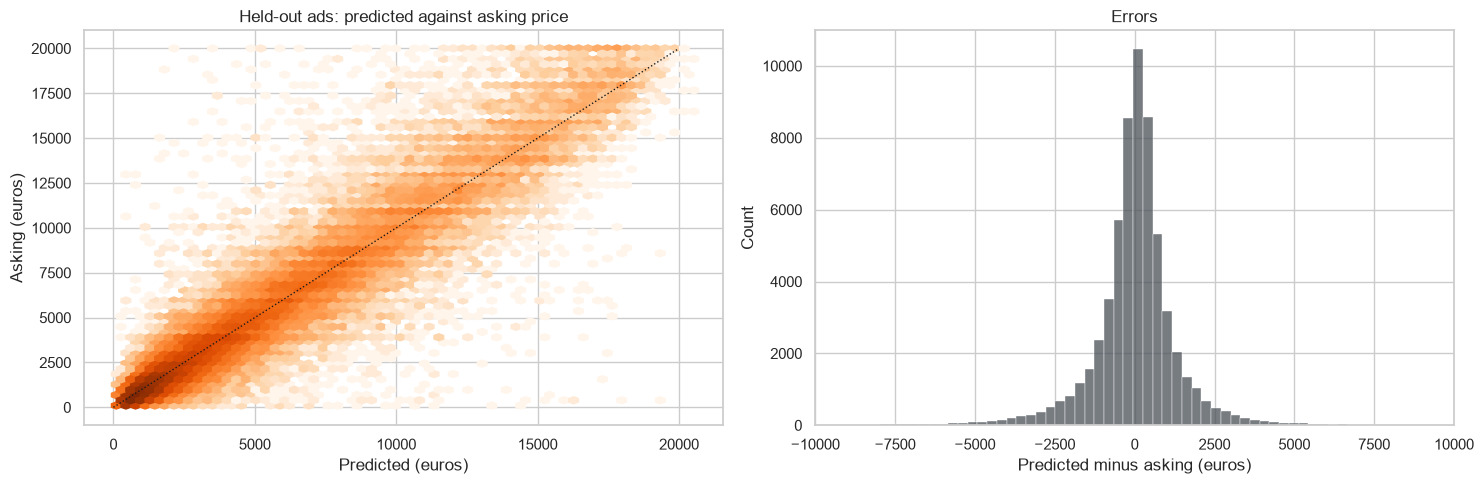

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].hexbin(pred, yt, gridsize=60, bins="log", cmap="Oranges", mincnt=1)
ax[0].plot([0, 20000], [0, 20000], "k:", lw=1)
ax[0].set(title="Held-out ads: predicted against asking price", xlabel="Predicted (euros)", ylabel="Asking (euros)")
sns.histplot(pred - yt, bins=120, ax=ax[1], color="#495057"); ax[1].set(title="Errors", xlabel="Predicted minus asking (euros)", xlim=(-10000, 10000))
plt.tight_layout(); plt.show()

**Findings**
- The held-out RMSE matches the cross-validated one, so the model was not tuned to the test set.
- The 80% range holds about 80% of held-out asking prices.
- In percentage terms, cheap cars are hardest (a 300-euro error on a 600-euro car is half its price); above 6,000 euros
  the median error is about 12% or less. Like any regression model it pulls the extremes toward the middle.

### 6.3 What drives prices (SHAP values)

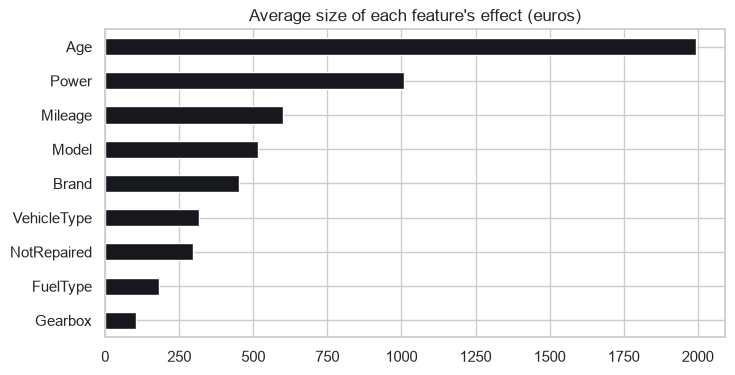

Age            1993.0
Power          1007.0
Mileage         601.0
Model           516.0
Brand           451.0
VehicleType     316.0
NotRepaired     296.0
FuelType        181.0
Gearbox         103.0
dtype: float64

In [26]:
sample = Xt.sample(5000, random_state=0)
contrib = final.booster_.predict(sample, pred_contrib=True)
shap = pd.DataFrame(contrib[:, :-1], columns=FEATURES)
assert np.allclose(contrib.sum(axis=1), final.booster_.predict(sample), atol=1e-3)  # contributions add up to the prediction
importance = shap.abs().mean().sort_values()
importance.plot.barh(figsize=(8, 4), color="#16181d", title="Average size of each feature's effect (euros)"); plt.show()
importance.sort_values(ascending=False).round(0)

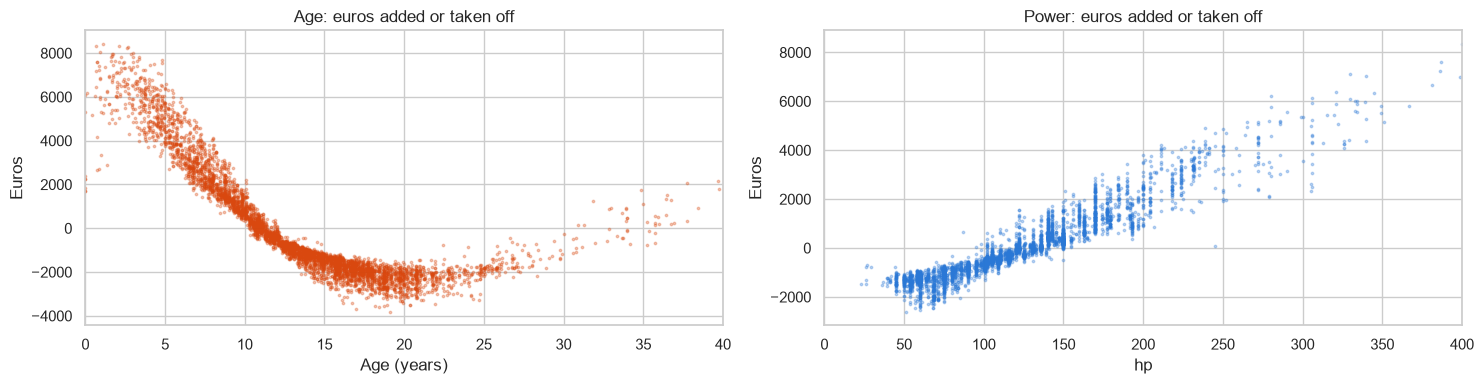

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].scatter(sample["Age"], shap["Age"], s=3, alpha=0.3, color="#d9480f"); ax[0].set(title="Age: euros added or taken off", xlabel="Age (years)", ylabel="Euros", xlim=(0, 40))
ax[1].scatter(sample["Power"], shap["Power"], s=3, alpha=0.3, color="#2a78d6"); ax[1].set(title="Power: euros added or taken off", xlabel="hp", ylabel="Euros", xlim=(0, 400))
plt.tight_layout(); plt.show()

Age moves a price most, then power, then mileage; model and brand together come next. Each prediction splits exactly
into one euro amount per feature, which the app shows as an itemised price build-up.

## 7 Saving the model

The model is saved as LightGBM's text format with a metadata file (features, category lists, settings, the range
table and the test results). The app's `train.py` reproduces the same model from `car_data.csv`.

In [28]:
out = Path("model"); out.mkdir(exist_ok=True)
final.booster_.save_model(str(out / "fairtag_lightgbm.txt"))
meta = dict(model="LightGBM gradient-boosted trees (regression, squared error)", target="Price (euros)", features=FEATURES,
            categorical=CATEGORICAL, categories=cats, params=PARAMS,
            range=dict(cover=[0.1, 0.9], edges=edges, low_ratio=low, high_ratio=high),
            rows=dict(raw=len(raw), clean=len(df), train=len(train), test=len(test)), cleaning=steps, cv=cv, test=held_out,
            comparison=[dict(model=k, **{m: round(v, 4) for m, v in r.items()}) for k, r in results.items()],
            timing=dict(fit_s=round(fit_s, 1), predict_ms=round(predict_ms, 2)),
            versions=dict(lightgbm=lgb.__version__, pandas=pd.__version__, numpy=np.__version__), built=str(date.today()))
(out / "metadata.json").write_text(json.dumps(meta, indent=1), encoding="utf-8")
(out / "comparison.json").write_text(json.dumps(meta["comparison"], indent=1), encoding="utf-8")
print(sorted(p.name for p in out.iterdir()))

['comparison.json', 'fairtag_lightgbm.txt', 'metadata.json']


In [29]:
# Reload and check the saved model gives the same predictions
reloaded = lgb.Booster(model_file=str(out / "fairtag_lightgbm.txt"))
assert np.allclose(np.maximum(reloaded.predict(Xt.iloc[:1000]), MIN_PRICE), pred[:1000])
print("saved model verified")

saved model verified


## 8 Conclusions

**Data.** 354,369 ads became 309,303 after removing reposts (10,194), placeholder prices (13,036), impossible
registration years (13,589) and ads under a year old with more than 50,000 km (8,247). Diesel was relabelled (it was
called "gasoline"), impossible power was set to missing, and age was measured to the month.

**Quality, speed and training time** (5-fold cross-validation, default settings):

| Model | RMSE (euros) | Training time per fold | Prediction, one car |
|---|---|---|---|
| Linear regression (sanity check) | 2,631 | 1 s | 4 ms |
| Decision tree | 1,832 | 1 s | 4 ms |
| Random forest | 1,590 | 9 s | 30 ms |
| **LightGBM** | **1,518** | **7 s** | **15 ms** |
| XGBoost | 1,540 | 19 s | 14 ms |
| CatBoost | 1,548 | 158 s | 1 ms |

**The model.** LightGBM gives the best quality and trains in seconds. Tuning moved its cross-validated RMSE only from
1,518 to 1,512 euros: the 24 settings tried all scored between 1,512 and 1,525, so the data, not the settings, limits
accuracy. Asking prices for similar cars vary widely because ads do not record condition, history or equipment.

**One test on 61,861 held-out ads:** RMSE **1,500 euros**, MAE 917, R² **0.891**; 52% of prices within 20%; the 80%
price range holds **80.4%** of real asking prices. The final model trains in about 16 seconds and prices a car in a
few milliseconds. The app deploys a lighter setting from the same search (11 MB instead of 48 MB) that scores 1,502 euros on the same held-out ads (section 5).

**Recommendation for Rusty Bargain.** Use LightGBM: the most accurate model, fast to train and to predict. Show the
price with its range rather than as a single number, and the euro breakdown of what each detail adds or takes off.
Watch cheap cars (under 1,000 euros), where percentage errors are largest. The model is live in the
[FairTag app](https://fairtag-car-valuation-application.streamlit.app/).